In [1]:
import numpy as np
import pandas as pd
import scipy.optimize
import matplotlib.pyplot as plt
import math
import pyperclip
import os
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.stats import norm

import sys
import beam_analysis as ba

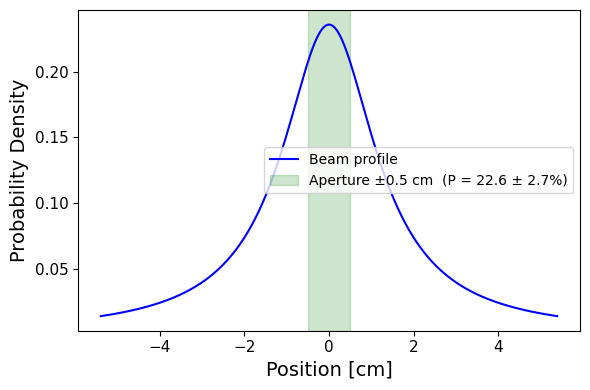

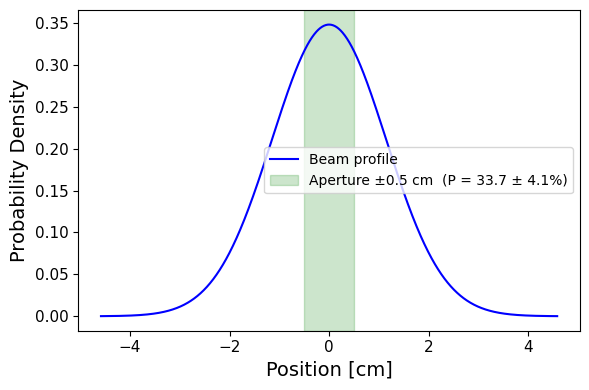

In [5]:
x = ba.capture_efficiency_lor(
    div_deg=1.4,
    div_deg_err=0.2,
    z_thou=100,
    z_thou_err=10,
    distance_nozzle_to_z1=0,
    plot=True
)
x = ba.capture_efficiency_gauss(
    div_deg=1.4,
    div_deg_err=0.2,
    z_thou=100,
    z_thou_err=10,
    distance_nozzle_to_z1=0,
    plot=True
)



# Rb, 101225 Data

get file data

In [2]:
results_folder_101225 = "results/results_101225"

# Near 101225, Zone 1 Meth

Gaussian

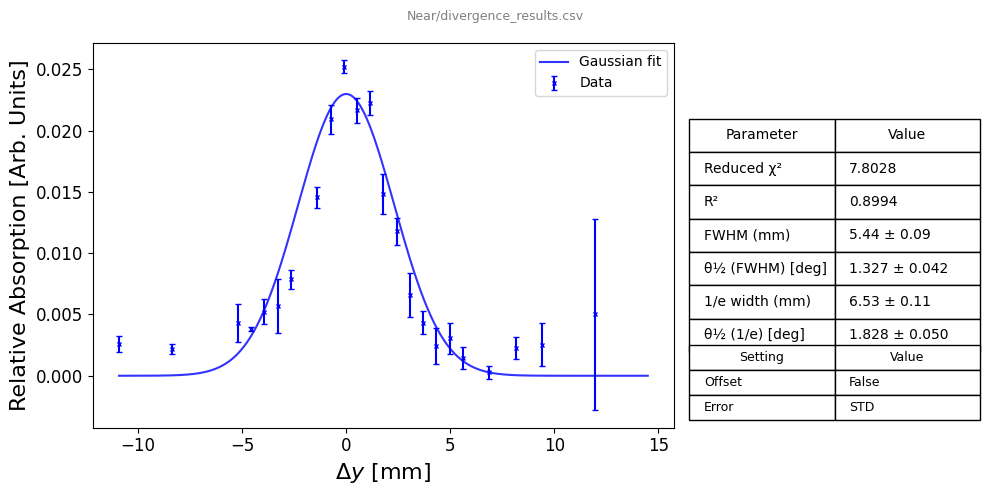

Reduced χ²: 7.8028  |  R²: 0.8994
Rb Flux [atoms/s]:              2.62e+10
θ½ FWHM [deg]:                  1.327 ± 0.042
Capture Efficiency [%]:         35.30 ± 0.83


In [3]:
# divergence
div_results_gaus_101225 = ba.divergence_fitting_gaus(results_folder_101225, "Near/divergence_results.csv", offset= False, error="STD", plot=True)

# get Rb flux
flux_file = os.path.join(results_folder_101225, "Near/flux_data", "flux_results.csv")
flux_results_gaus_101225 = ba.flux_from_divergence_gaus(flux_file, div_results_gaus_101225, center_x_thou=450, T_oven_C= 230, plot= False)

# capture eff
capture_gaus_101225 = ba.capture_efficiency_gauss(
    div_deg=div_results_gaus_101225['divhalfangle_FWHM'],
    div_deg_err=div_results_gaus_101225['divhalfangle_FWHM_err'],
    z_thou=div_results_gaus_101225['FWHM'] * 39.3701,   # mm → thou
    z_thou_err=div_results_gaus_101225['FWHM_err'] * 39.3701,
    distance_nozzle_to_z1=2.46,
    plot=False
)

print(f"Reduced χ²: {div_results_gaus_101225['chi2_reduced']:.4f}  |  R²: {div_results_gaus_101225['r_squared']:.4f}")

print(f"Rb Flux [atoms/s]:              {flux_results_gaus_101225['Rb_flux_atoms_s']:.2e}")
print(f"θ½ FWHM [deg]:                  {div_results_gaus_101225['divhalfangle_FWHM']:.3f} ± {div_results_gaus_101225['divhalfangle_FWHM_err']:.3f}")
print(f"Capture Efficiency [%]:         {capture_gaus_101225['P']*100:.2f} ± {capture_gaus_101225['P_err']*100:.2f}")

Lorentzian

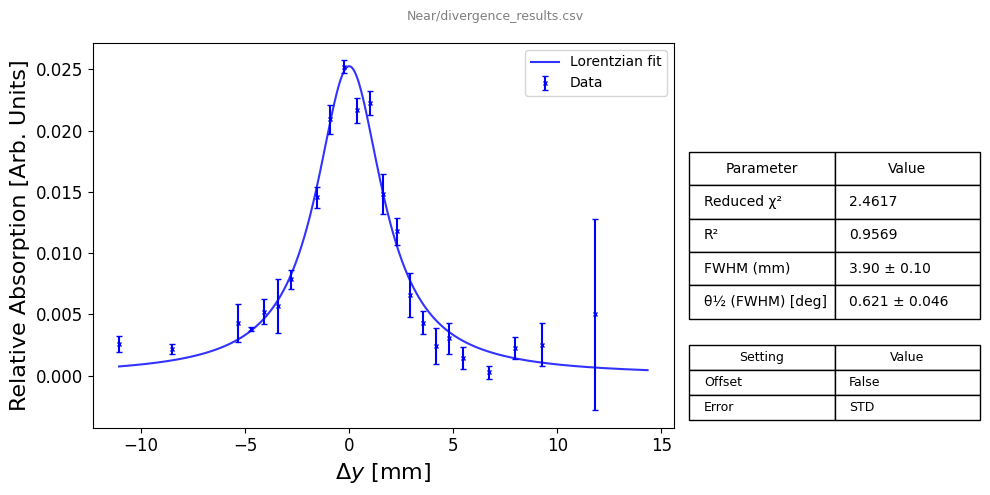

Reduced χ²: 2.4617  |  R²: 0.9569
Rb Flux [atoms/s]:              2.74e+10
θ½ FWHM [deg]:                  0.621 ± 0.046
Capture Efficiency [%]:         40.85 ± 1.62


In [4]:
# divergence
div_results_lor_101225 = ba.divergence_fitting_lor(results_folder_101225, "Near/divergence_results.csv", offset= False, error="STD", plot=True)

# get Rb flux
flux_file = os.path.join(results_folder_101225, "Near/flux_data", "flux_results.csv")
flux_results_lor_101225 = ba.flux_from_divergence_lor(flux_file, div_results_lor_101225, center_x_thou=450, T_oven_C= 230, plot= False)

# capture eff
capture_lor_101225 = ba.capture_efficiency_lor(
    div_deg=div_results_lor_101225['divhalfangle_FWHM'],
    div_deg_err=div_results_lor_101225['divhalfangle_FWHM_err'],
    z_thou=div_results_lor_101225['FWHM'] * 39.3701,   # mm → thou
    z_thou_err=div_results_lor_101225['FWHM_err'] * 39.3701,
    plot=False
)

print(f"Reduced χ²: {div_results_lor_101225['chi2_reduced']:.4f}  |  R²: {div_results_lor_101225['r_squared']:.4f}")
print(f"Rb Flux [atoms/s]:              {flux_results_lor_101225['Rb_flux_atoms_s']:.2e}")
print(f"θ½ FWHM [deg]:                  {div_results_lor_101225['divhalfangle_FWHM']:.3f} ± {div_results_lor_101225['divhalfangle_FWHM_err']:.3f}")
print(f"Capture Efficiency [%]:         {capture_lor_101225['P']*100:.2f} ± {capture_lor_101225['P_err']*100:.2f}")

# Far 101225 Zone 1 Meth

Gaus

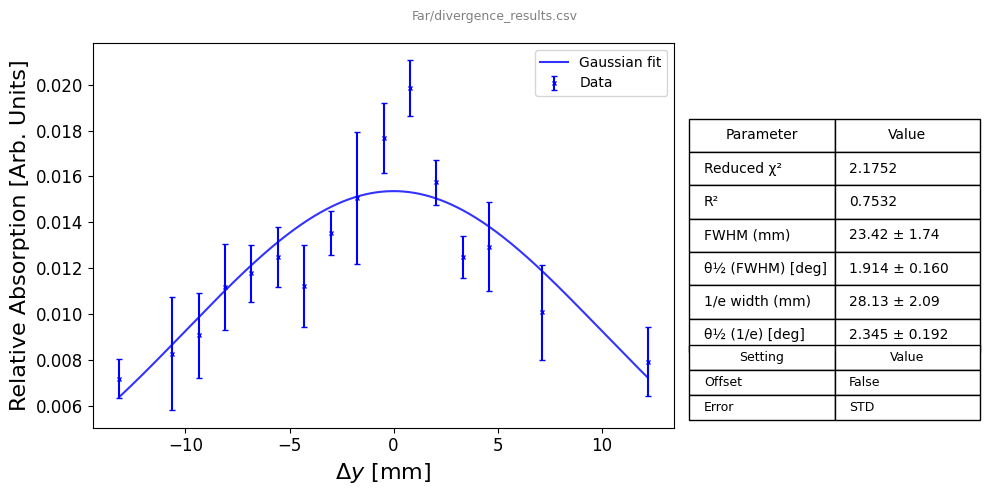

Reduced χ²: 2.1752  |  R²: 0.7532
Rb Flux [atoms/s]:              3.17e+10
θ½ FWHM [deg]:                  1.914 ± 0.160
Capture Efficiency [%]:         25.67 ± 1.40


In [5]:
# divergence
div_results_gaus_101225_far = ba.divergence_fitting_gaus(results_folder_101225, "Far/divergence_results.csv", offset= False, error="STD", plot=True, distancenozzle=12.3)

# get Rb flux
flux_file = os.path.join(results_folder_101225, "Far/flux_data", "flux_results.csv")
flux_results_gaus_101225_far = ba.flux_from_divergence_gaus(flux_file, div_results_gaus_101225_far, center_x_thou=500, T_oven_C= 230, plot= False)

# capture eff
capture_gaus_101225_far = ba.capture_efficiency_gauss(
    div_deg=div_results_gaus_101225_far['divhalfangle_FWHM'],
    div_deg_err=div_results_gaus_101225_far['divhalfangle_FWHM_err'],
    z_thou=div_results_gaus_101225_far['FWHM'] * 39.3701,   # mm → thou
    z_thou_err=div_results_gaus_101225_far['FWHM_err'] * 39.3701,
    distance_nozzle_to_z1=12.3,
    plot=False
)

print(f"Reduced χ²: {div_results_gaus_101225_far['chi2_reduced']:.4f}  |  R²: {div_results_gaus_101225_far['r_squared']:.4f}")
print(f"Rb Flux [atoms/s]:              {flux_results_gaus_101225_far['Rb_flux_atoms_s']:.2e}")
print(f"θ½ FWHM [deg]:                  {div_results_gaus_101225_far['divhalfangle_FWHM']:.3f} ± {div_results_gaus_101225_far['divhalfangle_FWHM_err']:.3f}")
print(f"Capture Efficiency [%]:         {capture_gaus_101225_far['P']*100:.2f} ± {capture_gaus_101225_far['P_err']*100:.2f}")

Lorentzian

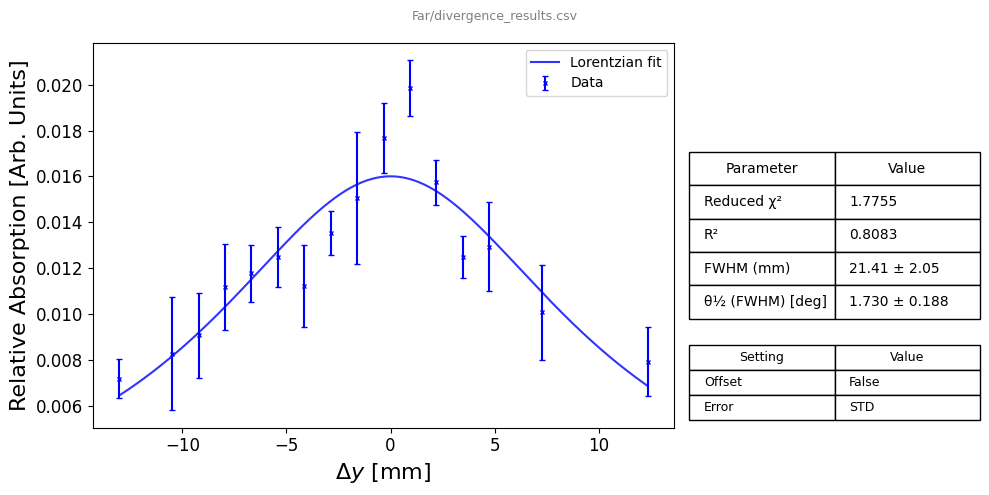

Reduced χ²: 1.7755  |  R²: 0.8083
Rb Flux [atoms/s]:              3.09e+10
θ½ FWHM [deg]:                  1.730 ± 0.188
Capture Efficiency [%]:         18.87 ± 1.30


In [6]:
# divergence
div_results_lor_101225_far = ba.divergence_fitting_lor(results_folder_101225, "Far/divergence_results.csv", offset= False, error="STD", plot=True, distancenozzle=12.3)

# get Rb flux
flux_file = os.path.join(results_folder_101225, "Far/flux_data", "flux_results.csv")
flux_results_lor_101225_far = ba.flux_from_divergence_lor(flux_file, div_results_lor_101225_far, center_x_thou=500, T_oven_C= 230, plot= False)

# capture eff
capture_lor_101225_far = ba.capture_efficiency_lor(
    div_deg=div_results_lor_101225_far['divhalfangle_FWHM'],
    div_deg_err=div_results_lor_101225_far['divhalfangle_FWHM_err'],
    z_thou=div_results_lor_101225_far['FWHM'] * 39.3701,   # mm → thou
    z_thou_err=div_results_lor_101225_far['FWHM_err'] * 39.3701,
    distance_nozzle_to_z1=12.3,
    plot=False
)

print(f"Reduced χ²: {div_results_lor_101225_far['chi2_reduced']:.4f}  |  R²: {div_results_lor_101225_far['r_squared']:.4f}")
print(f"Rb Flux [atoms/s]:              {flux_results_lor_101225_far['Rb_flux_atoms_s']:.2e}")
print(f"θ½ FWHM [deg]:                  {div_results_lor_101225_far['divhalfangle_FWHM']:.3f} ± {div_results_lor_101225_far['divhalfangle_FWHM_err']:.3f}")
print(f"Capture Efficiency [%]:         {capture_lor_101225_far['P']*100:.2f} ± {capture_lor_101225_far['P_err']*100:.2f}")

# 2 Zone, Meth 2

Meth 2 using Gaussian

In [7]:
# ── Divergence from FWHM growth between near and far ─────────────────────────
FWHM_near = div_results_gaus_101225['FWHM']           # mm
FWHM_far  = div_results_gaus_101225_far['FWHM']       # mm
FWHM_near_err = div_results_gaus_101225['FWHM_err']
FWHM_far_err  = div_results_gaus_101225_far['FWHM_err']

dist_near = 2.46   * 25.4  # in → mm
dist_far  = 12.3   * 25.4  # in → mm

delta_FWHM     = FWHM_far - FWHM_near
delta_dist     = dist_far - dist_near

# half-angle: beam grows by delta_FWHM/2 on each side over delta_dist
divhalfangle_geometric     = math.atan((delta_FWHM / 2) / delta_dist)
divhalfangle_geometric_deg = math.degrees(divhalfangle_geometric)

# error propagation
ddiv_dFWHM_far  =  (1 / (1 + ((delta_FWHM/2)/delta_dist)**2)) * (1 / (2 * delta_dist))
ddiv_dFWHM_near = -(1 / (1 + ((delta_FWHM/2)/delta_dist)**2)) * (1 / (2 * delta_dist))
divhalfangle_geometric_err = math.degrees(math.sqrt((ddiv_dFWHM_far * FWHM_far_err)**2 + (ddiv_dFWHM_near * FWHM_near_err)**2))

capture_gaus_101225_geometric = ba.capture_efficiency_gauss(
    div_deg=divhalfangle_geometric_deg,
    div_deg_err=divhalfangle_geometric_err,
    z_thou=div_results_gaus_101225['FWHM'] * 39.3701,
    z_thou_err=div_results_gaus_101225['FWHM_err'] * 39.3701,
    distance_nozzle_to_z1=2.46,
    plot=False
)

print(f"FWHM near: {FWHM_near:.2f} ± {FWHM_near_err:.2f} mm")
print(f"FWHM far:  {FWHM_far:.2f} ± {FWHM_far_err:.2f} mm")
print(f"θ½ geometric [deg]: {divhalfangle_geometric_deg:.3f} ± {divhalfangle_geometric_err:.3f}")
print(f"Capture Efficiency (geometric) [%]: {capture_gaus_101225_geometric['P']*100:.2f} ± {capture_gaus_101225_geometric['P_err']*100:.2f}")

FWHM near: 5.44 ± 0.09 mm
FWHM far:  23.42 ± 1.74 mm
θ½ geometric [deg]: 2.061 ± 0.200
Capture Efficiency (geometric) [%]: 25.02 ± 2.00


Lorentzian

In [8]:
# ── Divergence from FWHM growth between near and far ─────────────────────────
FWHM_near = div_results_lor_101225['FWHM']
FWHM_far  = div_results_lor_101225_far['FWHM']
FWHM_near_err = div_results_lor_101225['FWHM_err']
FWHM_far_err  = div_results_lor_101225_far['FWHM_err']

dist_near = 2.46   * 25.4  # in → mm
dist_far  = 12.3   * 25.4  # in → mm

delta_FWHM     = FWHM_far - FWHM_near
delta_dist     = dist_far - dist_near

divhalfangle_geometric     = math.atan((delta_FWHM / 2) / delta_dist)
divhalfangle_geometric_deg = math.degrees(divhalfangle_geometric)

ddiv_dFWHM_far  =  (1 / (1 + ((delta_FWHM/2)/delta_dist)**2)) * (1 / (2 * delta_dist))
ddiv_dFWHM_near = -(1 / (1 + ((delta_FWHM/2)/delta_dist)**2)) * (1 / (2 * delta_dist))
divhalfangle_geometric_err = math.degrees(math.sqrt((ddiv_dFWHM_far * FWHM_far_err)**2 + (ddiv_dFWHM_near * FWHM_near_err)**2))

capture_lor_101225_geometric = ba.capture_efficiency_lor(
    div_deg=divhalfangle_geometric_deg,
    div_deg_err=divhalfangle_geometric_err,
    z_thou=div_results_lor_101225['FWHM'] * 39.3701,
    z_thou_err=div_results_lor_101225['FWHM_err'] * 39.3701,
    distance_nozzle_to_z1=2.46,
    plot=False
)

print(f"FWHM near: {FWHM_near:.2f} ± {FWHM_near_err:.2f} mm")
print(f"FWHM far:  {FWHM_far:.2f} ± {FWHM_far_err:.2f} mm")
print(f"θ½ geometric [deg]: {divhalfangle_geometric_deg:.3f} ± {divhalfangle_geometric_err:.3f}")
print(f"Capture Efficiency (geometric) [%]: {capture_lor_101225_geometric['P']*100:.2f} ± {capture_lor_101225_geometric['P_err']*100:.2f}")

FWHM near: 3.90 ± 0.10 mm
FWHM far:  21.41 ± 2.05 mm
θ½ geometric [deg]: 2.007 ± 0.235
Capture Efficiency (geometric) [%]: 17.93 ± 1.77


# Far modified (Grain of Salt as remove "bad" data, but not good explanation)

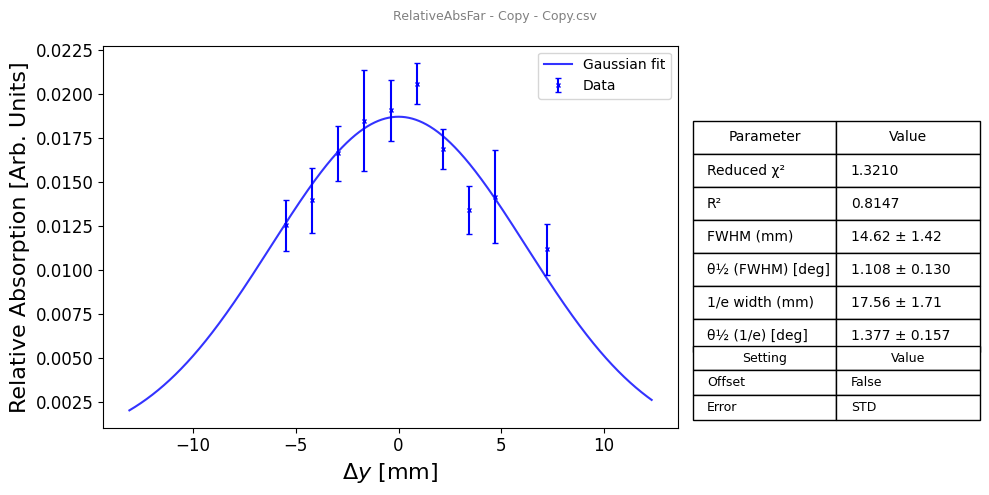

Reduced χ²: 1.3210  |  R²: 0.8147
Rb Flux [atoms/s]:              2.68e+10
θ½ FWHM [deg]:                  1.108 ± 0.130
Capture Efficiency [%]:         40.96 ± 2.82


In [9]:
# divergence
div_results_gaus_101225_far = ba.divergence_fitting_gaus(results_folder_101225, "RelativeAbsFar - Copy - Copy.csv", offset= False, error="STD", plot=True, distancenozzle=12.3)

# get Rb flux
flux_file = os.path.join(results_folder_101225, "Far/flux_data", "flux_results.csv")
flux_results_gaus_101225_far = ba.flux_from_divergence_gaus(flux_file, div_results_gaus_101225_far, center_x_thou=500, T_oven_C= 230, plot= False)

# capture eff
capture_gaus_101225_far = ba.capture_efficiency_gauss(
    div_deg=div_results_gaus_101225_far['divhalfangle_FWHM'],
    div_deg_err=div_results_gaus_101225_far['divhalfangle_FWHM_err'],
    z_thou=div_results_gaus_101225_far['FWHM'] * 39.3701,   # mm → thou
    z_thou_err=div_results_gaus_101225_far['FWHM_err'] * 39.3701,
    distance_nozzle_to_z1=12.3,
    plot=False
)

print(f"Reduced χ²: {div_results_gaus_101225_far['chi2_reduced']:.4f}  |  R²: {div_results_gaus_101225_far['r_squared']:.4f}")
print(f"Rb Flux [atoms/s]:              {flux_results_gaus_101225_far['Rb_flux_atoms_s']:.2e}")
print(f"θ½ FWHM [deg]:                  {div_results_gaus_101225_far['divhalfangle_FWHM']:.3f} ± {div_results_gaus_101225_far['divhalfangle_FWHM_err']:.3f}")
print(f"Capture Efficiency [%]:         {capture_gaus_101225_far['P']*100:.2f} ± {capture_gaus_101225_far['P_err']*100:.2f}")

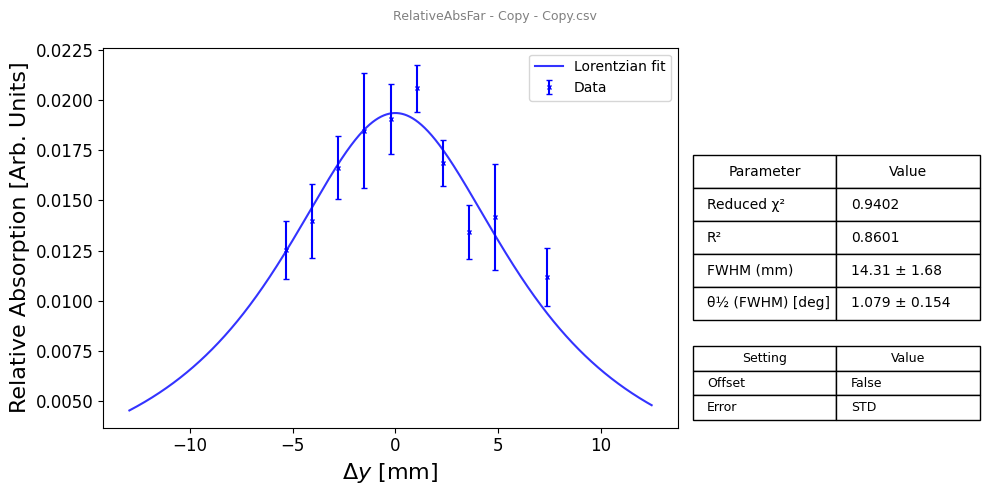

Reduced χ²: 0.9402  |  R²: 0.8601
Rb Flux [atoms/s]:              2.81e+10
θ½ FWHM [deg]:                  1.079 ± 0.154
Capture Efficiency [%]:         27.86 ± 2.24


In [10]:
# divergence
div_results_lor_101225_far = ba.divergence_fitting_lor(results_folder_101225, "RelativeAbsFar - Copy - Copy.csv", offset= False, error="STD", plot=True, distancenozzle=12.3)



# get Rb flux
flux_file = os.path.join(results_folder_101225, "Far/flux_data", "flux_results.csv")
flux_results_lor_101225_far = ba.flux_from_divergence_lor(flux_file, div_results_lor_101225_far, center_x_thou=500, T_oven_C= 230, plot= False)


# capture eff
capture_lor_101225_far = ba.capture_efficiency_lor(
    div_deg=div_results_lor_101225_far['divhalfangle_FWHM'],
    div_deg_err=div_results_lor_101225_far['divhalfangle_FWHM_err'],
    z_thou=div_results_lor_101225_far['FWHM'] * 39.3701,   # mm → thou
    z_thou_err=div_results_lor_101225_far['FWHM_err'] * 39.3701,
    distance_nozzle_to_z1=12.3,
    plot=False
)

print(f"Reduced χ²: {div_results_lor_101225_far['chi2_reduced']:.4f}  |  R²: {div_results_lor_101225_far['r_squared']:.4f}")
print(f"Rb Flux [atoms/s]:              {flux_results_lor_101225_far['Rb_flux_atoms_s']:.2e}")
print(f"θ½ FWHM [deg]:                  {div_results_lor_101225_far['divhalfangle_FWHM']:.3f} ± {div_results_lor_101225_far['divhalfangle_FWHM_err']:.3f}")
print(f"Capture Efficiency [%]:         {capture_lor_101225_far['P']*100:.2f} ± {capture_lor_101225_far['P_err']*100:.2f}")

# Zone 2 Modified (Grain of Salt as remove "bad" data, but not good explanation)

Gauss

In [11]:
# ── Divergence from FWHM growth between near and far ─────────────────────────
FWHM_near = div_results_gaus_101225['FWHM']           # mm
FWHM_far  = div_results_gaus_101225_far['FWHM']       # mm
FWHM_near_err = div_results_gaus_101225['FWHM_err']
FWHM_far_err  = div_results_gaus_101225_far['FWHM_err']

dist_near = 2.46   * 25.4  # in → mm
dist_far  = 12.3   * 25.4  # in → mm

delta_FWHM     = FWHM_far - FWHM_near
delta_dist     = dist_far - dist_near

# half-angle: beam grows by delta_FWHM/2 on each side over delta_dist
divhalfangle_geometric     = math.atan((delta_FWHM / 2) / delta_dist)
divhalfangle_geometric_deg = math.degrees(divhalfangle_geometric)

# error propagation
ddiv_dFWHM_far  =  (1 / (1 + ((delta_FWHM/2)/delta_dist)**2)) * (1 / (2 * delta_dist))
ddiv_dFWHM_near = -(1 / (1 + ((delta_FWHM/2)/delta_dist)**2)) * (1 / (2 * delta_dist))
divhalfangle_geometric_err = math.degrees(math.sqrt((ddiv_dFWHM_far * FWHM_far_err)**2 + (ddiv_dFWHM_near * FWHM_near_err)**2))

capture_gaus_101225_geometric = ba.capture_efficiency_lor(
    div_deg=divhalfangle_geometric_deg,
    div_deg_err=divhalfangle_geometric_err,
    z_thou=div_results_lor_101225['FWHM'] * 39.3701,
    z_thou_err=div_results_lor_101225['FWHM_err'] * 39.3701,
    distance_nozzle_to_z1=2.46,
    plot=False
)

print(f"FWHM near: {FWHM_near:.2f} ± {FWHM_near_err:.2f} mm")
print(f"FWHM far:  {FWHM_far:.2f} ± {FWHM_far_err:.2f} mm")
print(f"θ½ geometric [deg]: {divhalfangle_geometric_deg:.3f} ± {divhalfangle_geometric_err:.3f}")
print(f"Capture Efficiency (geometric) [%]: {capture_gaus_101225_geometric['P']*100:.2f} ± {capture_gaus_101225_geometric['P_err']*100:.2f}")

FWHM near: 5.44 ± 0.09 mm
FWHM far:  14.62 ± 1.42 mm
θ½ geometric [deg]: 1.053 ± 0.163
Capture Efficiency (geometric) [%]: 29.55 ± 3.19


Lorentzian

In [12]:
# ── Divergence from FWHM growth between near and far ─────────────────────────
FWHM_near = div_results_lor_101225['FWHM']
FWHM_far  = div_results_lor_101225_far['FWHM']
FWHM_near_err = div_results_lor_101225['FWHM_err']
FWHM_far_err  = div_results_lor_101225_far['FWHM_err']

dist_near = 2.46   * 25.4  # in → mm
dist_far  = 12.3   * 25.4  # in → mm

delta_FWHM     = FWHM_far - FWHM_near
delta_dist     = dist_far - dist_near

divhalfangle_geometric     = math.atan((delta_FWHM / 2) / delta_dist)
divhalfangle_geometric_deg = math.degrees(divhalfangle_geometric)

ddiv_dFWHM_far  =  (1 / (1 + ((delta_FWHM/2)/delta_dist)**2)) * (1 / (2 * delta_dist))
ddiv_dFWHM_near = -(1 / (1 + ((delta_FWHM/2)/delta_dist)**2)) * (1 / (2 * delta_dist))
divhalfangle_geometric_err = math.degrees(math.sqrt((ddiv_dFWHM_far * FWHM_far_err)**2 + (ddiv_dFWHM_near * FWHM_near_err)**2))

capture_lor_101225_geometric = ba.capture_efficiency_lor(
    div_deg=divhalfangle_geometric_deg,
    div_deg_err=divhalfangle_geometric_err,
    z_thou=div_results_lor_101225['FWHM'] * 39.3701,
    z_thou_err=div_results_lor_101225['FWHM_err'] * 39.3701,
    distance_nozzle_to_z1=2.46,
    plot=False
)

print(f"FWHM near: {FWHM_near:.2f} ± {FWHM_near_err:.2f} mm")
print(f"FWHM far:  {FWHM_far:.2f} ± {FWHM_far_err:.2f} mm")
print(f"θ½ geometric [deg]: {divhalfangle_geometric_deg:.3f} ± {divhalfangle_geometric_err:.3f}")
print(f"Capture Efficiency (geometric) [%]: {capture_lor_101225_geometric['P']*100:.2f} ± {capture_lor_101225_geometric['P_err']*100:.2f}")

FWHM near: 3.90 ± 0.10 mm
FWHM far:  14.31 ± 1.68 mm
θ½ geometric [deg]: 1.193 ± 0.193
Capture Efficiency (geometric) [%]: 27.03 ± 3.18


# Rb-AR, 112825 Data

get file data

In [13]:
results_folder_112825 = "results/results_112825"
divergence_file_name_112825 = "divergence_results.csv"

Gaussian Version

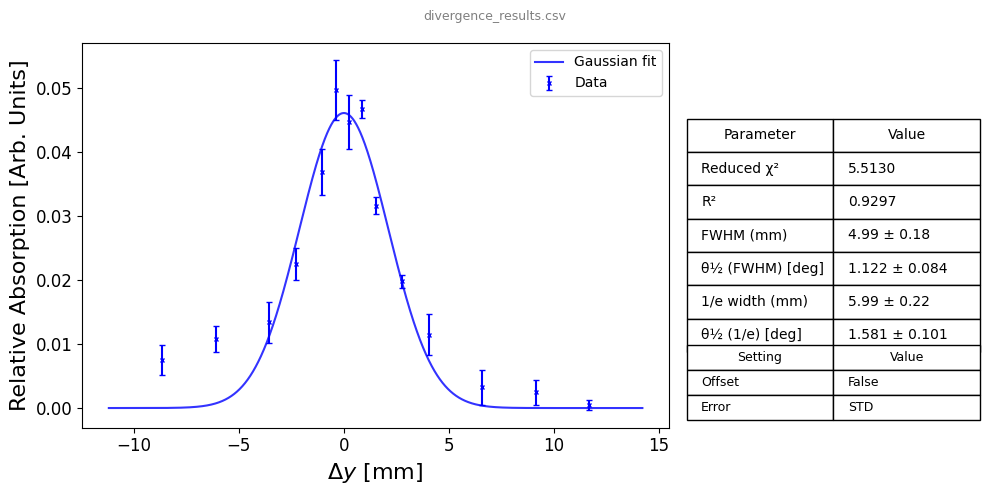

Reduced χ²: 5.5130  |  R²: 0.9297
Rb Flux [atoms/s]:              2.46e+10
Ar Flux [atoms/s]:              4.48e+15
Ar Flow [g/h]:                  0.0011
Rb Dopant Density [atoms/cm^3]: 1.47e+17
θ½ FWHM [deg]:                  1.122 ± 0.084
Capture Efficiency [%]:         40.55 ± 2.17


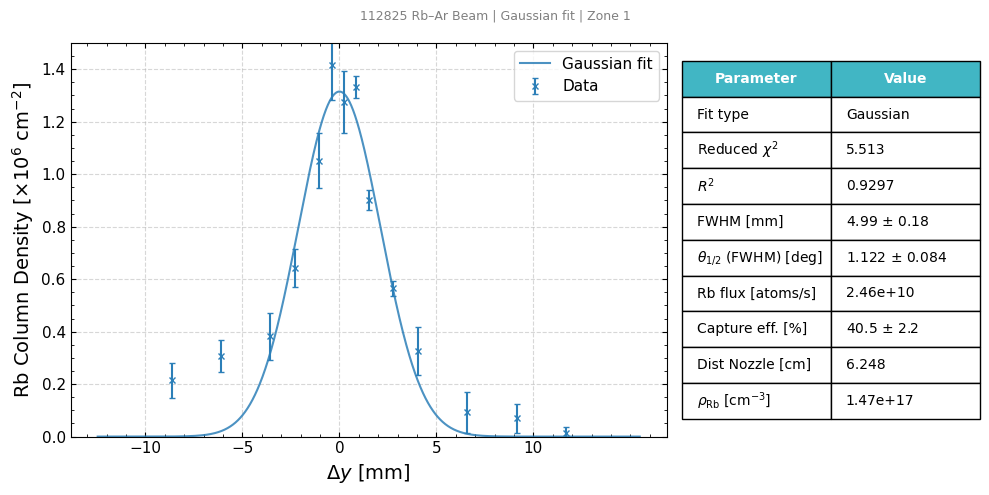

In [14]:
# divergence
div_results_gaus_112825 = ba.divergence_fitting_gaus(results_folder_112825, divergence_file_name_112825, offset= False, error="STD", plot=True)

# get Rb flux
flux_file = os.path.join(results_folder_112825, "flux_data", "flux_results.csv")
flux_results_gaus_112825 = ba.flux_from_divergence_gaus(flux_file, div_results_gaus_112825, center_x_thou=450, T_oven_C= 230, plot= False)

# capture eff
capture_gaus_112825 = ba.capture_efficiency_gauss(
    div_deg=div_results_gaus_112825['divhalfangle_FWHM'],
    div_deg_err=div_results_gaus_112825['divhalfangle_FWHM_err'],
    z_thou=div_results_gaus_112825['FWHM'] * 39.3701,   # mm → thou
    z_thou_err=div_results_gaus_112825['FWHM_err'] * 39.3701,
    plot=False
)


# get dopant density
Ar_flux, Rb_dopant_density, mass_flow_g_hr = ba.dopant_density(Ar_flow_sccm=0.01, Rb_flux=flux_results_gaus_112825["Rb_flux_atoms_s"])

print(f"Reduced χ²: {div_results_gaus_112825['chi2_reduced']:.4f}  |  R²: {div_results_gaus_112825['r_squared']:.4f}")
print(f"Rb Flux [atoms/s]:              {flux_results_gaus_112825['Rb_flux_atoms_s']:.2e}")
print(f"Ar Flux [atoms/s]:              {Ar_flux:.2e}")
print(f"Ar Flow [g/h]:                  {mass_flow_g_hr:.4f}")
print(f"Rb Dopant Density [atoms/cm^3]: {Rb_dopant_density:.2e}")
print(f"θ½ FWHM [deg]:                  {div_results_gaus_112825['divhalfangle_FWHM']:.3f} ± {div_results_gaus_112825['divhalfangle_FWHM_err']:.3f}")
print(f"Capture Efficiency [%]:         {capture_gaus_112825['P']*100:.2f} ± {capture_gaus_112825['P_err']*100:.2f}")

ba.plot_beam_summary(
    div_results_gaus_112825,
    flux_results_gaus_112825,
    capture_gaus_112825,
    dopant_density_cm3=Rb_dopant_density,
    fit_type="gaussian",
    title="112825 Rb–Ar Beam | Gaussian fit | Zone 1"
)

Lorentzian Version

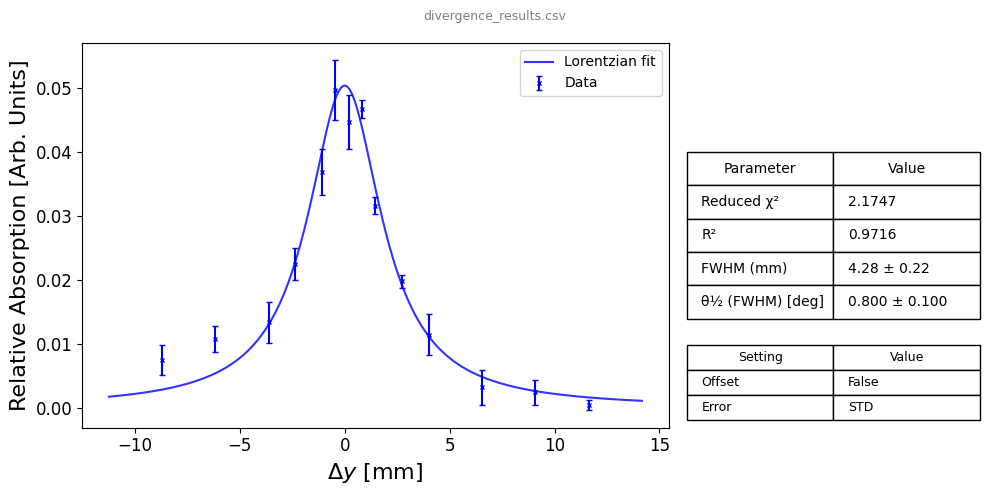

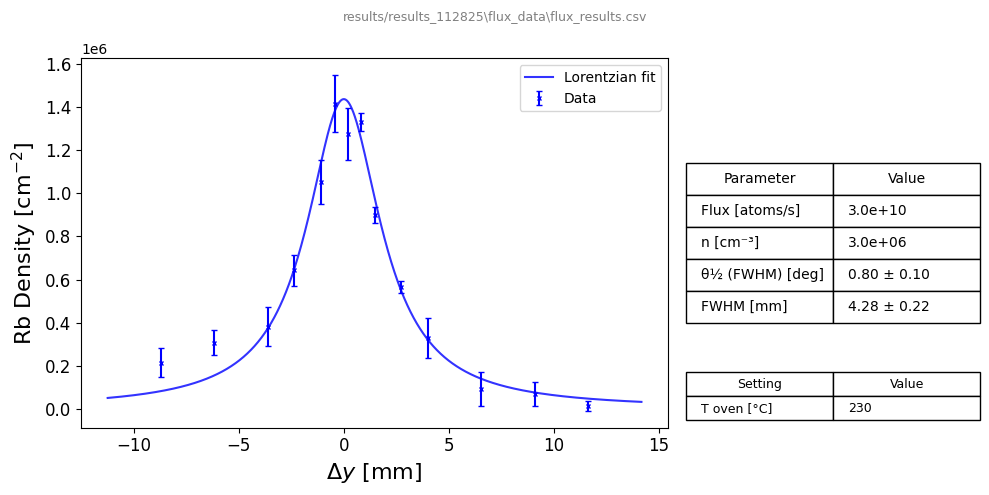

Reduced χ²: 2.1747  |  R²: 0.9716
Rb Flux [atoms/s]:              3.05e+10
Ar Flux [atoms/s]:              4.48e+15
Ar Flow [g/h]:                  0.0011
Rb Dopant Density [atoms/cm^3]: 1.81e+17
θ½ FWHM [deg]:                  0.800 ± 0.100
Capture Efficiency [%]:         34.69 ± 2.63


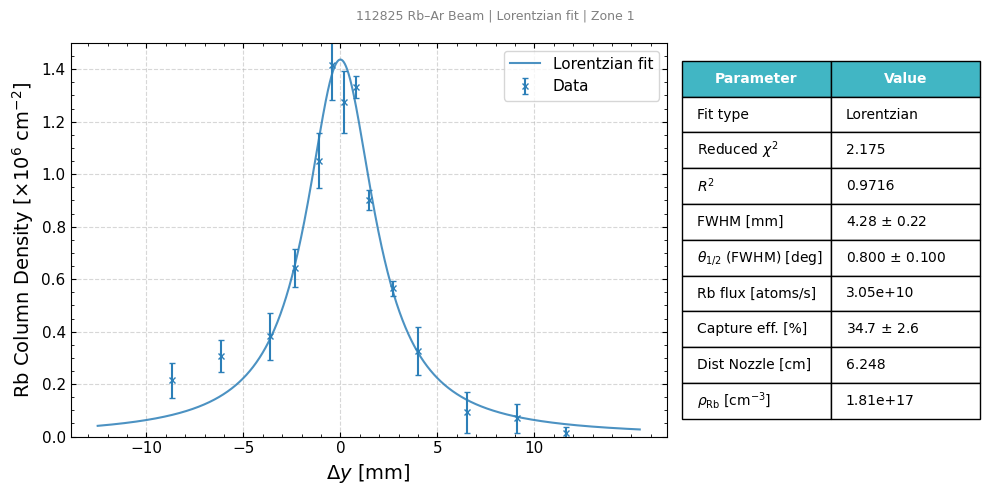

In [15]:
# divergence
div_results_lor_112825 = ba.divergence_fitting_lor(results_folder_112825, divergence_file_name_112825, offset= False, error="STD", plot=True)

# get Rb flux
flux_file = os.path.join(results_folder_112825, "flux_data", "flux_results.csv")
flux_results_lor_112825 = ba.flux_from_divergence_lor(flux_file, div_results_lor_112825, center_x_thou=450, T_oven_C= 230, plot= True)

# capture eff
capture_lor_112825 = ba.capture_efficiency_lor(
    div_deg=div_results_lor_112825['divhalfangle_FWHM'],
    div_deg_err=div_results_lor_112825['divhalfangle_FWHM_err'],
    z_thou=div_results_lor_112825['FWHM'] * 39.3701,   # mm → thou
    z_thou_err=div_results_lor_112825['FWHM_err'] * 39.3701,
    plot=False
)


# get dopant density
Ar_flux, Rb_dopant_density, mass_flow_g_hr = ba.dopant_density(Ar_flow_sccm=0.01, Rb_flux=flux_results_lor_112825["Rb_flux_atoms_s"])

print(f"Reduced χ²: {div_results_lor_112825['chi2_reduced']:.4f}  |  R²: {div_results_lor_112825['r_squared']:.4f}")
print(f"Rb Flux [atoms/s]:              {flux_results_lor_112825['Rb_flux_atoms_s']:.2e}")
print(f"Ar Flux [atoms/s]:              {Ar_flux:.2e}")
print(f"Ar Flow [g/h]:                  {mass_flow_g_hr:.4f}")
print(f"Rb Dopant Density [atoms/cm^3]: {Rb_dopant_density:.2e}")
print(f"θ½ FWHM [deg]:                  {div_results_lor_112825['divhalfangle_FWHM']:.3f} ± {div_results_lor_112825['divhalfangle_FWHM_err']:.3f}")
print(f"Capture Efficiency [%]:         {capture_lor_112825['P']*100:.2f} ± {capture_lor_112825['P_err']*100:.2f}")

ba.plot_beam_summary(
    div_results_lor_112825,
    flux_results_lor_112825,
    capture_lor_112825,
    dopant_density_cm3=Rb_dopant_density,
    fit_type="lorentzian",
    title="112825 Rb–Ar Beam | Lorentzian fit | Zone 1"
)

# Convert ALL into nice plot, claude/check

Saved → C:\Users\ikcco\OneDrive\Desktop\IsaacCross_Thesis_Stuff\Thesis Figures\ch06_results\Summary Plots\beam_summary_101225_Rb_zone1_gaussian_gaussian_chi2_7p80_theta_1p327deg.png


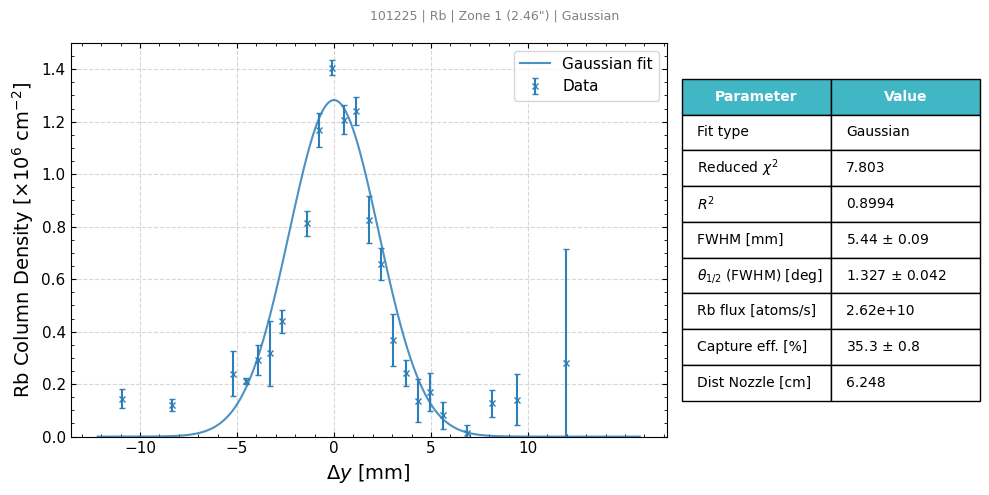

Saved → C:\Users\ikcco\OneDrive\Desktop\IsaacCross_Thesis_Stuff\Thesis Figures\ch06_results\Summary Plots\beam_summary_101225_Rb_zone1_lorentzian_lorentzian_chi2_2p46_theta_0p621deg.png


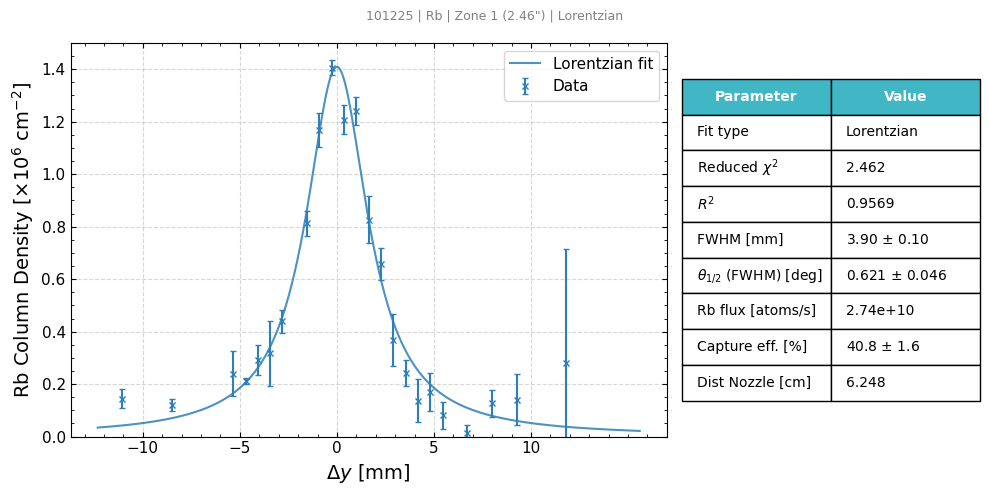

Saved → C:\Users\ikcco\OneDrive\Desktop\IsaacCross_Thesis_Stuff\Thesis Figures\ch06_results\Summary Plots\beam_summary_101225_Rb_zone2_gaussian_gaussian_chi2_2p18_theta_1p914deg.png


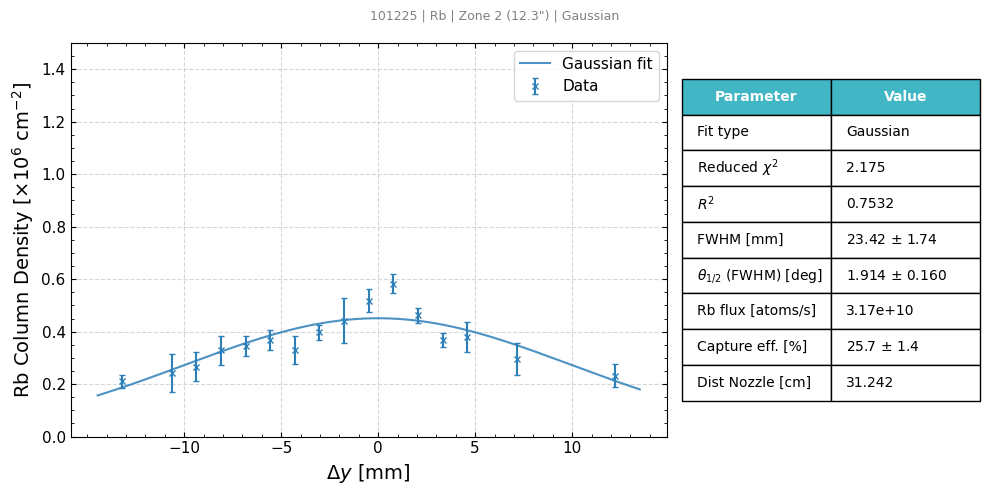

Saved → C:\Users\ikcco\OneDrive\Desktop\IsaacCross_Thesis_Stuff\Thesis Figures\ch06_results\Summary Plots\beam_summary_101225_Rb_zone2_lorentzian_lorentzian_chi2_1p78_theta_1p730deg.png


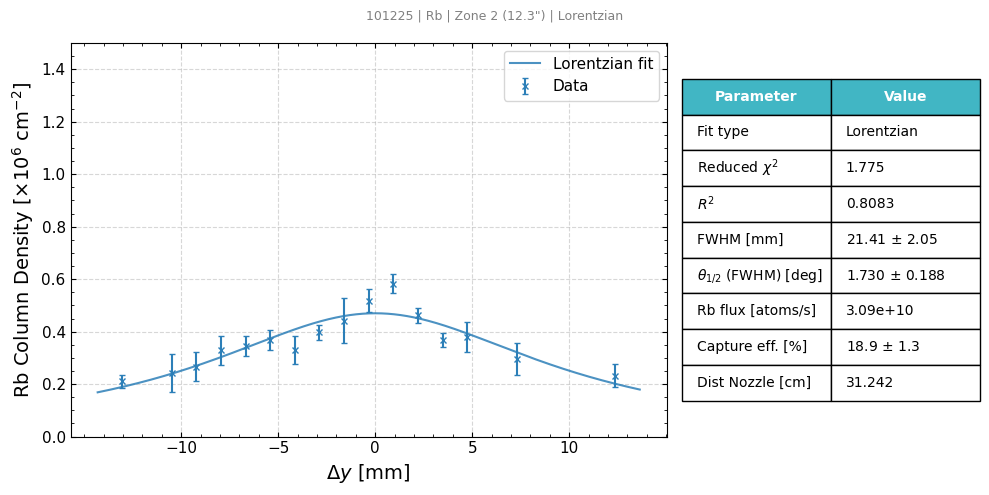

Saved → C:\Users\ikcco\OneDrive\Desktop\IsaacCross_Thesis_Stuff\Thesis Figures\ch06_results\Summary Plots\beam_summary_101225_Rb_zone2_mod_CAUTION_gaussian_gaussian_chi2_1p32_theta_1p108deg.png


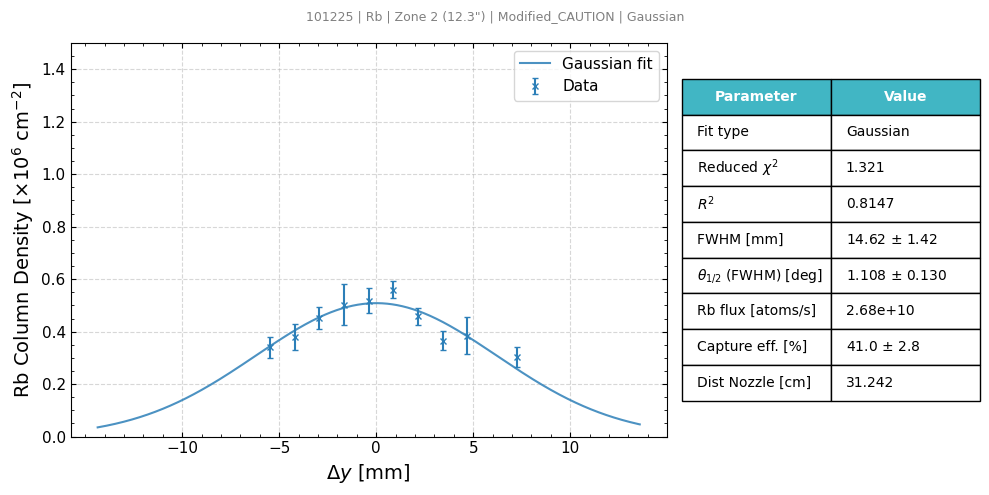

Saved → C:\Users\ikcco\OneDrive\Desktop\IsaacCross_Thesis_Stuff\Thesis Figures\ch06_results\Summary Plots\beam_summary_101225_Rb_zone2_mod_CAUTION_lorentzian_lorentzian_chi2_0p94_theta_1p079deg.png


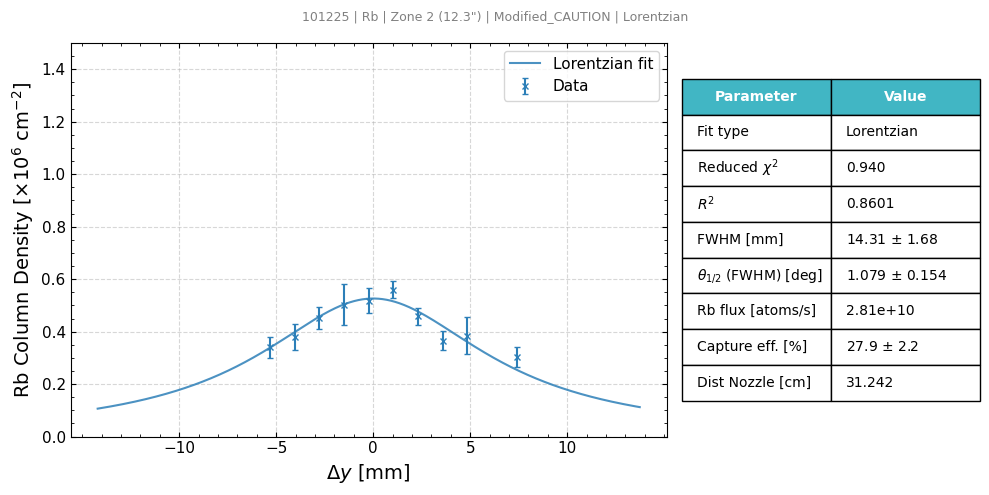

Saved → C:\Users\ikcco\OneDrive\Desktop\IsaacCross_Thesis_Stuff\Thesis Figures\ch06_results\Summary Plots\beam_summary_112825_RbAr_zone1_gaussian_gaussian_chi2_5p51_theta_1p122deg.png


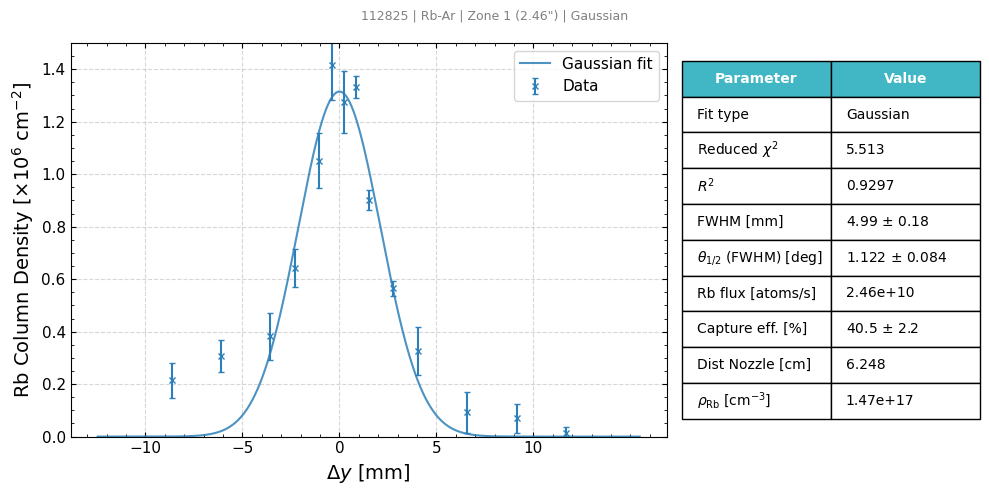

Saved → C:\Users\ikcco\OneDrive\Desktop\IsaacCross_Thesis_Stuff\Thesis Figures\ch06_results\Summary Plots\beam_summary_112825_RbAr_zone1_lorentzian_lorentzian_chi2_2p17_theta_0p800deg.png


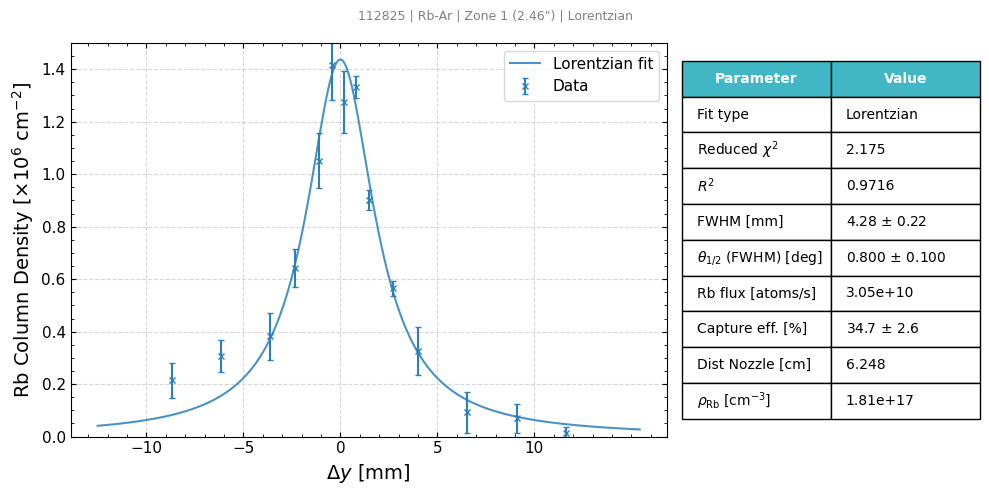


All plots saved to: C:\Users\ikcco\OneDrive\Desktop\IsaacCross_Thesis_Stuff\Thesis Figures\ch06_results\Summary Plots


In [16]:
# ── CONFIGURATION ─────────────────────────────────────────────────────────────
SAVE_DIR = r"C:\Users\ikcco\OneDrive\Desktop\IsaacCross_Thesis_Stuff\Thesis Figures\ch06_results\Summary Plots"
AR_FLOW_SCCM = 0.01

# ─────────────────────────────────────────────────────────────────────────────
def run_and_save(dataset_label, results_folder, div_file, flux_folder,
                 fit_type, distancenozzle, center_x_thou,
                 T_oven_C=230, ar_flow_sccm=None, title=None):

    if fit_type == "gaussian":
        div = ba.divergence_fitting_gaus(
            results_folder, div_file,
            offset=False, error="STD", plot=False,
            distancenozzle=distancenozzle
        )
    else:
        div = ba.divergence_fitting_lor(
            results_folder, div_file,
            offset=False, error="STD", plot=False,
            distancenozzle=distancenozzle
        )

    flux_file = os.path.join(results_folder, flux_folder, "flux_results.csv")
    if fit_type == "gaussian":
        flux = ba.flux_from_divergence_gaus(
            flux_file, div, center_x_thou=center_x_thou,
            T_oven_C=T_oven_C, plot=False
        )
    else:
        flux = ba.flux_from_divergence_lor(
            flux_file, div, center_x_thou=center_x_thou,
            T_oven_C=T_oven_C, plot=False
        )

    z_thou     = div['FWHM'] * 39.3701
    z_thou_err = div['FWHM_err'] * 39.3701
    if fit_type == "gaussian":
        cap = ba.capture_efficiency_gauss(
            div_deg=div['divhalfangle_FWHM'],
            div_deg_err=div['divhalfangle_FWHM_err'],
            z_thou=z_thou, z_thou_err=z_thou_err,
            distance_nozzle_to_z1=distancenozzle,
            plot=False
        )
    else:
        cap = ba.capture_efficiency_lor(
            div_deg=div['divhalfangle_FWHM'],
            div_deg_err=div['divhalfangle_FWHM_err'],
            z_thou=z_thou, z_thou_err=z_thou_err,
            distance_nozzle_to_z1=distancenozzle,
            plot=False
        )

    rho = None
    if ar_flow_sccm is not None:
        _, rho, _ = ba.dopant_density(
            Ar_flow_sccm=ar_flow_sccm,
            Rb_flux=flux["Rb_flux_atoms_s"]
        )

    ba.plot_beam_summary(
        div, flux, cap,
        dopant_density_cm3=rho,
        fit_type=fit_type,
        title=title,
        save_dir=SAVE_DIR,
        dataset_label=dataset_label
    )


# ── 101225 Rb — Near, Zone 1 (2.46") ─────────────────────────────────────────
for fit in ("gaussian", "lorentzian"):
    run_and_save(
        dataset_label  = f"101225_Rb_zone1_{fit}",
        results_folder = results_folder_101225,
        div_file       = "Near/divergence_results.csv",
        flux_folder    = "Near/flux_data",
        fit_type       = fit,
        distancenozzle = 2.46,
        center_x_thou  = 450,
        title          = f"101225 | Rb | Zone 1 (2.46\") | {fit.capitalize()}",
    )

# ── 101225 Rb — Far, Zone 2 (12.3") ──────────────────────────────────────────
for fit in ("gaussian", "lorentzian"):
    run_and_save(
        dataset_label  = f"101225_Rb_zone2_{fit}",
        results_folder = results_folder_101225,
        div_file       = "Far/divergence_results.csv",
        flux_folder    = "Far/flux_data",
        fit_type       = fit,
        distancenozzle = 12.3,
        center_x_thou  = 500,
        title          = f"101225 | Rb | Zone 2 (12.3\") | {fit.capitalize()}",
    )

# ── 101225 Rb — Far modified, Zone 2 (12.3") — CAUTION ───────────────────────
for fit in ("gaussian", "lorentzian"):
    run_and_save(
        dataset_label  = f"101225_Rb_zone2_mod_CAUTION_{fit}",
        results_folder = results_folder_101225,
        div_file       = "RelativeAbsFar - Copy - Copy.csv",
        flux_folder    = "Far/flux_data",
        fit_type       = fit,
        distancenozzle = 12.3,
        center_x_thou  = 500,
        title          = f"101225 | Rb | Zone 2 (12.3\") | Modified_CAUTION | {fit.capitalize()}",
    )

# ── 112825 Rb-Ar — Zone 1 (2.46") ────────────────────────────────────────────
for fit in ("gaussian", "lorentzian"):
    run_and_save(
        dataset_label  = f"112825_RbAr_zone1_{fit}",
        results_folder = results_folder_112825,
        div_file       = divergence_file_name_112825,
        flux_folder    = "flux_data",
        fit_type       = fit,
        distancenozzle = 2.46,
        center_x_thou  = 450,
        ar_flow_sccm   = AR_FLOW_SCCM,
        title          = f"112825 | Rb-Ar | Zone 1 (2.46\") | {fit.capitalize()}",
    )

print("\nAll plots saved to:", SAVE_DIR)